# Experiments: Baseline Model (ResNet50V2+LSTM)

- Tom
- November 20, 2026

This notebook builds a baseline model with ResNet50V2 and LSTM.

## Setup

### _Import the Necessary Libraries_

In [1]:
import copy as cp
import numpy as np
import cv2
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from itertools import product
from IPython.display import display, HTML, Markdown
from tensorflow.keras import Sequential
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense, SimpleRNN, TimeDistributed
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score

In [2]:
SEED = 8

def set_random_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)

### _Load Original Video Clips_

In [3]:
# Locations of the shared data (relative to this notebook)
DATA_ROOT    = '../data/orig_data/'

# Split names used in the feature file names and as dictionary keys
TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'

In [4]:
def load_clip_info(data_root, data_type, scope=None):
    info_file = data_root + data_type + '.csv'
    df = pd.read_csv(info_file)
    if scope:
        df = df[df['label'].isin(scope)]

    return df

In [5]:
selected_classes = ['BodyWeightSquats', 'Lunges', 'PushUps', 'WallPushups',
                    'PullUps', 'HandstandPushups', 'JumpingJack', 'JumpRope']
clip_files_info = load_clip_info(DATA_ROOT, TRAIN, selected_classes)
clip_files_info['label'].unique()

<StringArray>
[     'JumpingJack',          'PullUps', 'BodyWeightSquats',
 'HandstandPushups',      'WallPushups',         'JumpRope',
           'Lunges',          'PushUps']
Length: 8, dtype: str

In [6]:
label_dict = {}

for i in range(len(selected_classes)):
    label_dict[selected_classes[i]] = i

label_dict

{'BodyWeightSquats': 0,
 'Lunges': 1,
 'PushUps': 2,
 'WallPushups': 3,
 'PullUps': 4,
 'HandstandPushups': 5,
 'JumpingJack': 6,
 'JumpRope': 7}

In [7]:
def load_clip(clip_path, resize=None, n_frames=16):
    # create video capture entity
    cap = cv2.VideoCapture(clip_path)
    frames = []

    # read frames from the clip
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if resize:
            frame = cv2.resize(frame, resize)

        # Reorder to RGB, which the pretrained CNNs expect
        frame = cv2.cvtColor(frame, cv2.COLOR_BGRA2RGB)

        frames.append(frame)
    # ok, frame = cap.read() # Read the first frame
    # # Read every frame until the video ends
    # while ok:
    #     frame = cv2.resize(frame, (size, size)) # Resize the frame to (224, 224, 3)
    #     frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)) 
    #     ok, frame = cap.read() # Read the next frame
    cap.release() # Close video file
    # Get 32 evenly spaced frames
    indexes = np.linspace(0, len(frames) - 1, n_frames).astype(int)
    # Combine individual frame arrays into one array, keep the 32 chosen frames
    clip = np.stack(frames).astype(np.float32)[indexes]
    return preprocess_input(clip)

In [8]:
clip_path = DATA_ROOT + clip_files_info['clip_path'].values[0]
print(clip_path)
clip1 = load_clip(clip_path, (224, 224))

../data/orig_data//train/JumpingJack/v_JumpingJack_g13_c03.avi


In [9]:
clip1.shape

(16, 224, 224, 3)

In [10]:
def load_clips(clip_path, scope, frame_size=(224, 224), n_frames=16):
    """
    Load all of clips.
    """
    features = {}
    labels = {}

    for name in [TRAIN, VALIDATION, TEST]:
        X = []
        y = []
        clip_info = load_clip_info(clip_path, name, scope)

        # iterate all rows
        for row in clip_info.itertuples(index=False):
            label = label_dict[row.label]
            y.append(label)

            clip_file = clip_path + row.clip_path
            clip = load_clip(clip_file, frame_size, n_frames)

            X.append(clip)

        X = np.stack(X).astype(np.float32)
        y = np.array(y, dtype=np.int32)

        features[name] = X
        labels[name] = y

    return (features, labels)


In [11]:
features, labels = load_clips(DATA_ROOT, selected_classes)

In [12]:
features[TRAIN].shape

(723, 16, 224, 224, 3)

In [13]:
features[TEST].shape

(123, 16, 224, 224, 3)

In [14]:
labels[TEST]

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=int32)

## Build the Baseline Model

### _Visualization Functions_

In [15]:
def filter_parameter_value(k, v):
    if k == 'Hidden layers':
        layers = []
        for layer in v:
            layers.append(f'{layer["fn"].__name__}({layer["units"]})')
        return layers
    elif k == 'Optimizer':
        return v.__name__
    return v

def config_to_html(conf, ignore_name=True):
    # html_str = ""
    # for k, v in conf.items():
    #     if ignore_name and (k == 'Experiment Name' or k == 'Setting'):
    #         continue
    #     if not isinstance(v, (int, float, str, tuple, list)):
    #         v = v.__name__
        # html_str += f'''<p><span style="display: inline-block; width:150px; text-align: right">{k}</span>: {v}</p>'''
    html_str = " | ".join(
        f"{k}={filter_parameter_value(k, v)}"
        for k, v in conf.items()
        if not (ignore_name and k in ('Experiment Name', 'Setting', 'prefix', 'stored model name'))
    )        
    return html_str

def print_report(df, title=''):
    styled_df = (df.style.hide()
                 .set_properties(**{'text-align': 'center'})
                 .set_table_styles([
                     { 'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')] }
                 ])
                )
    
    if len(title) > 0:
        display(Markdown(f'__{title}__'))
    display(styled_df)
    
class Line(object):
    def __init__(self, data, label):
        self.data = data
        self.label = label

class Lines(object):
    def __init__(self, title, lines, xlabel, ylabel):
        self._title = title
        self._lines = lines
        self._xlabel = xlabel
        self._ylable = ylabel

    def plot(self, ax):
        for line in self._lines:
            ax.plot(line.data, label=line.label)

        ax.set_xlabel(self._xlabel)
        ax.set_ylabel(self._ylable)
        ax.legend()

def plot_twins_multiple_line_chart(lines):
    _, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    for i in range(2):
        lines[i].plot(axes[i])

    plt.tight_layout()
    plt.show()
    

def plot_training_history(history):
    # plot accuracy
    # Training Accuracy
    train_acc = Line(history['accuracy'], 'Training Accuracy')
    # Validation Accuracy
    val_acc = Line(history['val_accuracy'], 'Validation Accuracy')
    acc_lines = Lines('Accuracy Trend',
                      lines=[train_acc, val_acc],
                      xlabel='Epoch',
                      ylabel='Accuracy')
    
    # plot loss
    # Training Loss
    train_loss = Line(history['loss'], 'Training Loss')
    # Validation Loss
    val_loss = Line(history['val_loss'], 'Validation Loss')
    loss_lines = Lines('Loss Trend',
                       lines=[train_loss, val_loss],
                       xlabel='Epoch',
                       ylabel='Loss')

    plot_twins_multiple_line_chart([acc_lines, loss_lines])

### _Sequential Model Functions_

In [16]:
import time

class LatencyTracker(Callback):
    '''
        Keras callback that records how long each training epoch takes (in seconds).
    '''

    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [17]:
def create_optimizer(params):
    '''
        Build the optimizer named in the settings dict
        (Adam is the base model's).
    '''
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    return None

def get_layer_name(prefix, layer, idx):
    layer_name = f'{prefix}_{layer["fn"].__name__.lower()}'
    if idx:
        layer_name += f'_{idx}'
    return layer_name

def measure_prediction_latency(model, X_clips, n_clips=100):
    '''
        Average time (ms) to predict ONE clip, the way the live demo would.
        
        Note: this times the recurrent part only, because the CNN features
              are precomputed.
    '''
    clips = tf.constant(X_clips[:n_clips])
    # warm-up call so setup time isn't counted
    model(clips[:1], training=False) 

    start = time.time()
    for i in range(n_clips):
        # direct call with a batch of 1 = one clip
        model(clips[i:i + 1], training=False)

    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0):
    '''
        Build, train and evaluate one CNN-LSTM run, then add a row to `reports`.
    
        params: settings dict (copy of baseline_config with one value changed)
        X, y:   feature and label dicts from load_data()
        
        Results are judged on the validation set only; the test set is saved
        for the final model.
    '''
    if verbose == 0:
        # print experiment name only
        print(f"{params['Experiment Name']} ...", end=" ")
    start = time.time()

    # reset every random seed so the same settings always give the same result
    #tf.keras.utils.set_random_seed(SEED)
    set_random_seed(SEED)

    input_shape = X[TRAIN].shape[1:]   # (frames, feature size)
    
    # create model: recurrent layer -> dropout -> softmax output
    model = Sequential(name=params['Experiment Name'])
    model.add(Input(shape=input_shape))

    # add backbone ResNet50v2
    #model.add(ResNet50V2(name=f'{params['prefix']}_ResNet50V2'))
    resnet = ResNet50V2(
        weights="imagenet",
        include_top=False,
        pooling="avg",
        input_shape=(224, 224, 3)
    )
    #resnet.trainable = False
    model.add(TimeDistributed(resnet, name=f'{params['prefix']}_timedistrubed'))

    
    # for multiple recurrent layers
    hidden_layers = params['Hidden layers']
    layer_count = None
    if len(hidden_layers) > 1:
        layer_count = 1
        for layer in hidden_layers[:-1]:
            model.add(layer['fn'](layer['units'],
                                  name=get_layer_name(params['prefix'], layer, layer_count),
                                  return_sequences=True))
            layer_count += 1
    layer = hidden_layers[-1]
    model.add(layer['fn'](layer['units'],
                          name=get_layer_name(params['prefix'], layer, layer_count)))
    
    # model.add(Dropout(params['Droupout rate'], name=f'{params["prefix"]}_dropout'))
    model.add(Dense(params['Output'][0], activation=params['Output'][1], name='output'))
    
    # compile model
    optimizer = create_optimizer(params)
    model.compile(
        optimizer=optimizer,
        loss = params['Loss'],
        metrics = params['Metrics']
    )

    if verbose > 0:
        model.summary()

    # early-stopping moniters the validation loss
    early_stopping = EarlyStopping(monitor=params['Moniter'],
                                   patience=params['patience'],
                                   restore_best_weights=params['restore best weights'])
    
    # checkpoint save the best model
    checkpoint = ModelCheckpoint(
        params['stored model name'],
        monitor=params['Moniter'],
        save_best_only=True
    )
    
    # latency-tracker calculates and records the duration per epoch
    latency_tracker = LatencyTracker()
    
    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs = params['Epochs'],
                        batch_size = params['Batch size'],
                        callbacks = [early_stopping,
                                     checkpoint,
                                     latency_tracker],
                        verbose = verbose)
    
    # evaluate with testing data
    test_loss, test_accuracy = model.evaluate(X[TEST], y[TEST], verbose=verbose)
    
    # calculation for the report
    val_loss, val_accuracy   = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=verbose)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=verbose), axis=1)
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])
    
    report = {
        'Val accuracy': val_accuracy,
        'Val macro F1': val_f1,
        'Test Accuracy': test_accuracy,
        'Test Loss': test_loss,
        'Epochs run': len(history.history['loss']),
        'Latency (ms)': measure_prediction_latency(model, X[VALIDATION], 1),
        'Train time (s)': latency_tracker.total_latency,
        'Parameters': config_to_html(params),
    }
    
    if verbose == 0:
        print(f'({time.time() - start:.2f}s)', end=" ... ")
        # print_report(pd.DataFrame([report]), params['Experiment Name'])
    else:
        print_report(pd.DataFrame([report]))
        plot_training_history(history.history)
        
    # clean the model to release memory
    del history
    del model
    
    return report

### _Build the Baseline_

In [18]:
baseline_config = {}
baseline_config['Experiment Name']     = "Baseline"
baseline_config['prefix']  = 'base'
baseline_config['Setting'] = "-"

baseline_config['backbone layer'] = ResNet50V2
#baseline_config['Recurrent layer'] = LSTM
baseline_config['Hidden layers']    = [{ 'fn': LSTM, 'units': 256 }]
baseline_config['Droupout rate']   = 0.5
baseline_config['Output']          = (8, "softmax")
baseline_config['Optimizer']       = Adam
baseline_config['Learning rate']   = 0.001
baseline_config['Loss']            = "sparse_categorical_crossentropy"
baseline_config['Metrics']         = ["accuracy"]
baseline_config['Batch size']      = 32
baseline_config['Epochs']          = 100
baseline_config['F1 Average']      = "macro"
baseline_config['Moniter']         = "val_loss"
baseline_config['patience']        = 30
baseline_config['restore best weights'] = True
baseline_config['stored model name']    = "baseline_tom.keras"

Model: "Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ base_timedistrubed              │ (None, 16, 2048)       │    23,564,800 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_lstm (LSTM)                │ (None, 256)            │     2,360,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,927,176 (98.90 MB)

 Trainable params: 25,881,736 (98.73 MB)

 Non-trainable params: 45,440 (177.50 KB)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 513s 20s/step - accuracy: 0.6349 - loss: 1.1686 - val_accuracy: 0.7583 - val_loss: 0.7830
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 435s 19s/step - accuracy: 0.8409 - loss: 0.4952 - val_accuracy: 0.6833 - val_loss: 1.3134
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 453s 20s/step - accuracy: 0.7773 - loss: 0.7617 - val_accuracy: 0.7000 - val_loss: 0.9230
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 442s 19s/step - accuracy: 0.8852 - loss: 0.3740 - val_accuracy: 0.8833 - val_loss: 0.5385
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 445s 19s/step - accuracy: 0.8990 - loss: 0.3621 - val_accuracy: 0.7917 - val_loss: 0.7534
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 455s 20s/step - accuracy: 0.9391 - loss: 0.1953 - val_accuracy: 0.7250 - val_loss: 1.0340
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 472s 20s/step - accuracy: 0.9322 - loss: 0.2000 - val_accuracy: 0.8000 - val_loss: 0.7839
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 476s 21s/step - accuracy: 0.9225 - loss: 0.2647 - val_accu

Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Latency (ms),Train time (s),Parameters
0.991667,0.991622,0.967480,0.118480,100,1544.334173,41050.463215,"backbone layer= | Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"


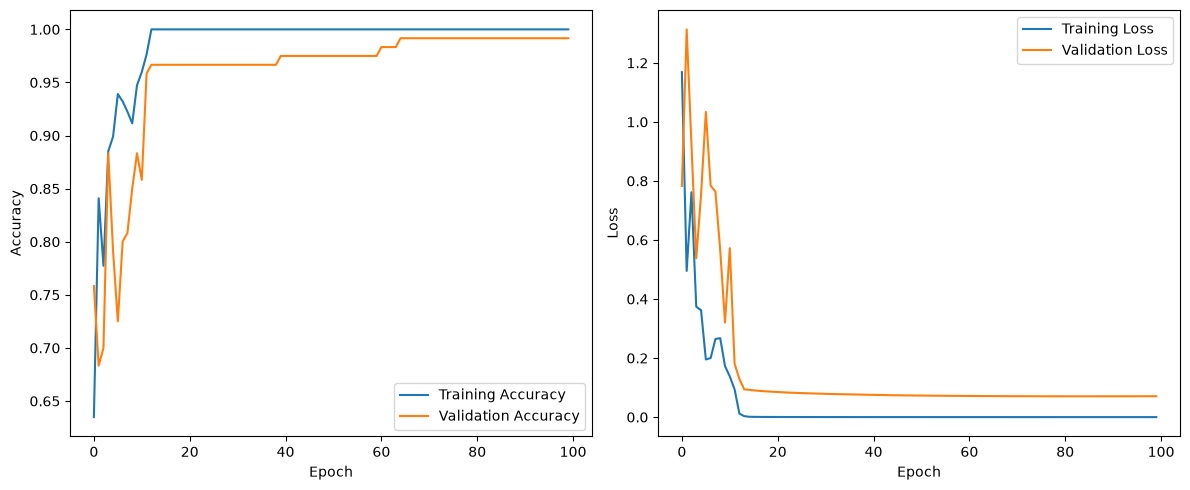

In [19]:
res = run_experiment(baseline_config, features, labels, verbose=1)

reports = []
res_ext = {
    'Run': baseline_config['Experiment Name'],
    'Setting': baseline_config['Setting']
}
res_ext.update(res)
reports.append(res_ext)